<a href="https://colab.research.google.com/github/mamiedovaelmira/online-store-sql-python-tableau/blob/main/Exploratory_data_analysis_for_online_store.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
from google.colab import auth
from google.cloud import bigquery

auth.authenticate_user()
project_id = 'data-analytics-mate'
client = bigquery.Client(project = project_id)



In [24]:
query = """
WITH sessions_info AS (
    SELECT
        s.date AS order_date,
        s.ga_session_id AS session_id,
        sp.continent,
        sp.country,
        sp.device,
        sp.browser,
        sp.mobile_model_name,
        sp.operating_system,
        sp.language AS browser_language,
        sp.name AS traffic_source,
        sp.channel AS traffic_channel
    FROM `data-analytics-mate.DA.session` AS s
    LEFT JOIN `data-analytics-mate.DA.session_params` AS sp
        ON s.ga_session_id = sp.ga_session_id
),

orders_info AS (
    SELECT
        o.ga_session_id,
        p.category,
        p.name AS product_name,
        p.price,
        p.short_description
    FROM `data-analytics-mate.DA.order` AS o
    LEFT JOIN `data-analytics-mate.DA.product` AS p
        ON o.item_id = p.item_id
),

accounts_info AS (
    SELECT
        acs.ga_session_id,
        acs.account_id,
        CASE
            WHEN acc.is_verified = 1 THEN True
            WHEN acc.is_verified = 0 THEN False
            ELSE NULL
        END AS email_confirmed,
        CASE
            WHEN acc.is_unsubscribed = 1 THEN False
            WHEN acc.is_unsubscribed = 0 THEN True
            ELSE NULL
        END AS is_subscribed
    FROM `data-analytics-mate.DA.account_session` AS acs
    LEFT JOIN `data-analytics-mate.DA.account` AS acc
        ON acs.account_id = acc.id
)

SELECT
    si.*,
    ai.account_id,
    ai.email_confirmed,
    ai.is_subscribed,
    oi.category,
    oi.product_name,
    oi.price,
    oi.short_description
FROM sessions_info AS si
LEFT JOIN orders_info AS oi
ON si.session_id = oi.ga_session_id
LEFT JOIN accounts_info AS ai
ON si.session_id = ai.ga_session_id
"""
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = client.query(query).to_dataframe(create_bqstorage_client=False)
print("First 5 Rows\n")
df.head()


First 5 Rows



,order_date,session_id,continent,country,device,browser,mobile_model_name,operating_system,browser_language,traffic_source,traffic_channel,account_id,email_confirmed,is_subscribed,category,product_name,price,short_description
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,<Other>,Paid Search,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,<Other>,Web,zh,(direct),Direct,<NA>,<NA>,<NA>,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,(direct),Direct,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en-us,(direct),Direct,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


#Data overview

In [25]:
print("DataFrame Structure\n")
df.info()

DataFrame Structure

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   order_date         349545 non-null  dbdate 
 1   session_id         349545 non-null  Int64  
 2   continent          349545 non-null  object 
 3   country            349545 non-null  object 
 4   device             349545 non-null  object 
 5   browser            349545 non-null  object 
 6   mobile_model_name  349545 non-null  object 
 7   operating_system   349545 non-null  object 
 8   browser_language   235279 non-null  object 
 9   traffic_source     349545 non-null  object 
 10  traffic_channel    349545 non-null  object 
 11  account_id         27945 non-null   Int64  
 12  email_confirmed    27945 non-null   boolean
 13  is_subscribed      27945 non-null   boolean
 14  category           33538 non-null   object 
 15  product_name       33538 non-n

In [26]:
#Dataset description
print(f"Total number of columns: {df.shape[1]}")
print(f"Total number of rows: {df.shape[0]}")

#Data types
print(f"\nDataset types: \n{df.dtypes.value_counts()}")
numeric = df.select_dtypes(include=['number']).columns.tolist()
print(f"\nNumeric Columns: {numeric}")
categorical = df.select_dtypes(include=['object', 'bool']).columns.tolist()
print(f"Categorical Columns: {categorical}")
datetime = df.select_dtypes(include=['dbdate']).columns.tolist()
print(f"Datetime Columns: {datetime}")

Total number of columns: 18
Total number of rows: 349545

Dataset types: 
object     12
boolean     2
Int64       2
dbdate      1
float64     1
Name: count, dtype: int64

Numeric Columns: ['session_id', 'account_id', 'price']
Categorical Columns: ['continent', 'country', 'device', 'browser', 'mobile_model_name', 'operating_system', 'browser_language', 'traffic_source', 'traffic_channel', 'email_confirmed', 'is_subscribed', 'category', 'product_name', 'short_description']
Datetime Columns: ['order_date']


In [27]:
#Period
print(f"\nPeriod: {df['order_date'].min()} — {df['order_date'].max()}")

#Unique values
unique_cnt = df[['session_id', 'continent', 'country', 'device', 'browser', 'category', 'browser_language', 'traffic_channel']].nunique()
print(f"\nNumber of unique values: \n{unique_cnt}")


Period: 2020-11-01 — 2021-01-31

Number of unique values: 
session_id          349545
continent                6
country                108
device                   3
browser                  6
category                14
browser_language         9
traffic_channel          5
dtype: int64


In [28]:
#Missing values
print(f"\nMissing values: \n{df.isnull().sum()}")


Missing values: 
order_date                0
session_id                0
continent                 0
country                   0
device                    0
browser                   0
mobile_model_name         0
operating_system          0
browser_language     114266
traffic_source            0
traffic_channel           0
account_id           321600
email_confirmed      321600
is_subscribed        321600
category             316007
product_name         316007
price                316007
short_description    316007
dtype: int64


Missing values description

There are many missing values ​​in browser_language column due to a technical issue with data collection, despite the fact that these values ​​weren't found, for example, in browser or device column. This happens because the device type or in browser is determined by the user agent string, which is much more difficult to block than the browser language.

Columns such as: account_id, email_confirmed, is_subscribed have missing values because most users access the site without registering (anonymously), so there is no information about their accounts in the system.

The columns storing product data (category, product_name, price,
short_description) contain empty values, ​​because no purchase was made during the session. This is a natural occurrence for any online store, as the number of sessions will always exceed the number of purchases by at least several times.

In [29]:
#Data cleaning
#Duplicates
if df.duplicated().any():
  print(f"Duplicates are found: {df[df.duplicated()]}")
else:
  print("Duplicates aren't found")

#Fill missed values
df['browser_language'] = df['browser_language'].fillna('Unknown')
df['price'] = df['price'].fillna(0) #For calculations change null to 0

#Check if price < 0
price_anomalies = df[df['price']< 0]
print (f"\nAnomalies in price: {len(price_anomalies)}")








Duplicates aren't found

Anomalies in price: 0


#Sales and user analysis


In [30]:
#New variable, because before it was specified that the null values ​​were changed to 0
purchases = df[df['price'] > 0]

#Top by orders and revenue
top_continents = purchases['continent'].value_counts().head(3)
print(f"Top 3 Continents by orders: \n{top_continents.map('{:,}'.format)}")
top_continents_by_sales = purchases.groupby('continent')['price'].sum().sort_values(ascending=False).head(3)
print(f"\nTop 3 Continents by revenue:\n {'$' + top_continents_by_sales.map('{:,}'.format)}")



Top 3 Continents by orders: 
continent
Americas    18,553
Asia         7,950
Europe       6,261
Name: count, dtype: object

Top 3 Continents by revenue:
 continent
Americas    $17,665,280.0
Asia         $7,601,298.3
Europe       $5,934,624.2
Name: price, dtype: object


In [31]:
top_countries = purchases['country'].value_counts().head(5)
print(f"\nTop 5 Countries by orders:\n{top_countries.map('{:,}'.format)}")
top_countries_by_sales = purchases.groupby('country')['price'].sum().sort_values(ascending=False).head(5)
print(f"\nTop 5 Countries by revenue:\n {'$' + top_countries_by_sales.map('{:,}'.format)}")


Top 5 Countries by orders:
country
United States     14,673
India              3,029
Canada             2,560
United Kingdom     1,029
France               678
Name: count, dtype: object

Top 5 Countries by revenue:
 country
United States     $13,943,553.9
India              $2,809,762.0
Canada             $2,437,921.0
United Kingdom       $938,317.9
France               $710,692.8
Name: price, dtype: object


In [32]:
#Top categories by revenue
revenue_categories = purchases.groupby('category')['price'].sum().sort_values(ascending=False).head(10)
print(f"Top 10 categories by revenue: {'$' + revenue_categories.map('{:,}'.format)}")


Top 10 categories by revenue: category
Sofas & armchairs                   $8,388,254.5
Chairs                              $6,147,748.8
Beds                                $4,919,725.0
Bookcases & shelving units          $3,640,818.1
Cabinets & cupboards                $2,336,499.5
Outdoor furniture                   $2,142,222.2
Tables & desks                      $1,790,307.5
Chests of drawers & drawer units      $906,562.5
Bar furniture                         $735,503.0
Children's furniture                  $467,697.0
Name: price, dtype: object


In [33]:
#Top USA revenue categories
top_usa_categories = purchases[purchases['country'] == 'United States'].groupby('category')['price'].sum().sort_values(ascending=False).head(10)
print(f"Top 10 categories by revenue in USA: \n{'$' + top_usa_categories.map('{:,}'.format)}")

Top 10 categories by revenue in USA: 
category
Sofas & armchairs                   $3,707,144.5
Chairs                              $2,619,773.8
Beds                                $2,213,058.0
Bookcases & shelving units          $1,567,606.9
Cabinets & cupboards                  $994,545.5
Outdoor furniture                     $929,245.2
Tables & desks                        $777,865.0
Chests of drawers & drawer units      $382,388.0
Bar furniture                         $330,805.0
Children's furniture                  $207,575.0
Name: price, dtype: object


In [34]:
#Sales analysis by type and model devices
total_revenue = purchases['price'].sum()
print(f"Total revenue: ${total_revenue:,}")

#device type
device_type_revenue = purchases.groupby('device')['price'].sum()
device_type_prcnt = (device_type_revenue / total_revenue * 100).sort_values(ascending=False)
print(f"\nRevenue by device: \n{device_type_prcnt.round(2).astype(str) + '%'}")


Total revenue: $31,971,731.1

Revenue by device: 
device
desktop     59.0%
mobile     38.73%
tablet      2.26%
Name: price, dtype: object


In [35]:
#model type
model_revenue = purchases.groupby('mobile_model_name')['price'].sum()
model_revenue_prcnt = (model_revenue / total_revenue * 100).sort_values(ascending=False)
print(f"\nRevenue by model: \n{model_revenue_prcnt.round(2).astype(str) + '%'}")


Revenue by model: 
mobile_model_name
Chrome        27.84%
<Other>       20.44%
Safari         20.3%
iPhone        20.08%
ChromeBook     5.73%
Edge           2.18%
iPad            1.4%
Firefox        1.32%
Pixel 4 XL     0.37%
Pixel 3        0.34%
Name: price, dtype: object


In [36]:
#Sales by traffic source
source_revenue = purchases.groupby('traffic_source')['price'].sum()
source_revenue_prcnt = (source_revenue / total_revenue * 100).sort_values(ascending=False)
print(f"Revenue by traffic source: \n{source_revenue_prcnt.round(2).astype(str) + '%'}")

Revenue by traffic source: 
traffic_source
(organic)          34.2%
(direct)          23.44%
<Other>           18.45%
(referral)        17.65%
(data deleted)     6.26%
Name: price, dtype: object


In [37]:
# % of registered users with confirmed email
reg_users = df[df['account_id'].notnull()]
total_reg_users = len(reg_users)
print(f"Total registered users: {total_reg_users:,}")

confirmed_cnt = reg_users['email_confirmed'].sum()
print(f"Count of confirmed email: {confirmed_cnt:,}")

confirmed_cnt_prcnt = (confirmed_cnt / total_reg_users) * 100
print(f"Registered users with confirmed email: {confirmed_cnt_prcnt:.2f}%")

Total registered users: 27,945
Count of confirmed email: 20,036
Registered users with confirmed email: 71.70%


In [38]:
# % of registered users who unsubscribed
subscribed_users = df[df['is_subscribed'].notnull()]
unsubscribed_cnt = (subscribed_users['is_subscribed'] == False).sum()
print(f"Count of unsubscribed users: {unsubscribed_cnt}")

total_reg = len(subscribed_users)
unsubscribed_cnt_prcnt = (unsubscribed_cnt / total_reg) * 100
print(f"Registered users who unsubscribed: {unsubscribed_cnt_prcnt:,.2f}%")


Count of unsubscribed users: 4735
Registered users who unsubscribed: 16.94%


In [39]:
# Sales compare subscribed vs unsubscribed users
#Grouping data by each user
users = df.groupby('account_id').agg({'price': 'sum', 'is_subscribed': 'first'}).reset_index()
users['total_orders'] = (users['price'] > 0)

#Grouping by subscription
comparison = users.groupby('is_subscribed').agg({'account_id': 'count', 'price': 'sum', 'total_orders': 'sum'})

# Rename columns
comparison = comparison.rename(columns={'account_id': 'total_users', 'price': 'total_revenue'})

#ARPU
comparison['arpu'] = comparison['total_revenue'] / comparison['total_users']
# Calculate conversion - % of total subscribed/unsubscribed users who made the order
comparison['conversion_%'] = (comparison['total_orders'] / comparison['total_users']) * 100

fixed_comparison = comparison.style.format({'total_users': '{:,}', 'total_revenue': '${:,.2f}', 'total_orders': '{:,}',
                                            'arpu': '${:,.2f}', 'conversion_%': '{:.2f}%'})
print("Comparison users Subscribed VS Unsubscribed")
display(fixed_comparison)

Comparison users Subscribed VS Unsubscribed


,total_users,total_revenue,total_orders,arpu,conversion_%
is_subscribed,,,,,
False,"4,735","$431,721.60",447,$91.18,9.44%
True,"23,210","$2,150,796.90","2,334",$92.67,10.06%


In [40]:
#Top countries by registered users
top_reg_countries = reg_users.groupby('country')['account_id'].nunique().sort_values(ascending=False).head(3)
print(f"Top 3 Countries by registered users: \n{top_reg_countries.map('{:,}'.format)}")

Top 3 Countries by registered users: 
country
United States    12,384
India             2,687
Canada            2,067
Name: account_id, dtype: object


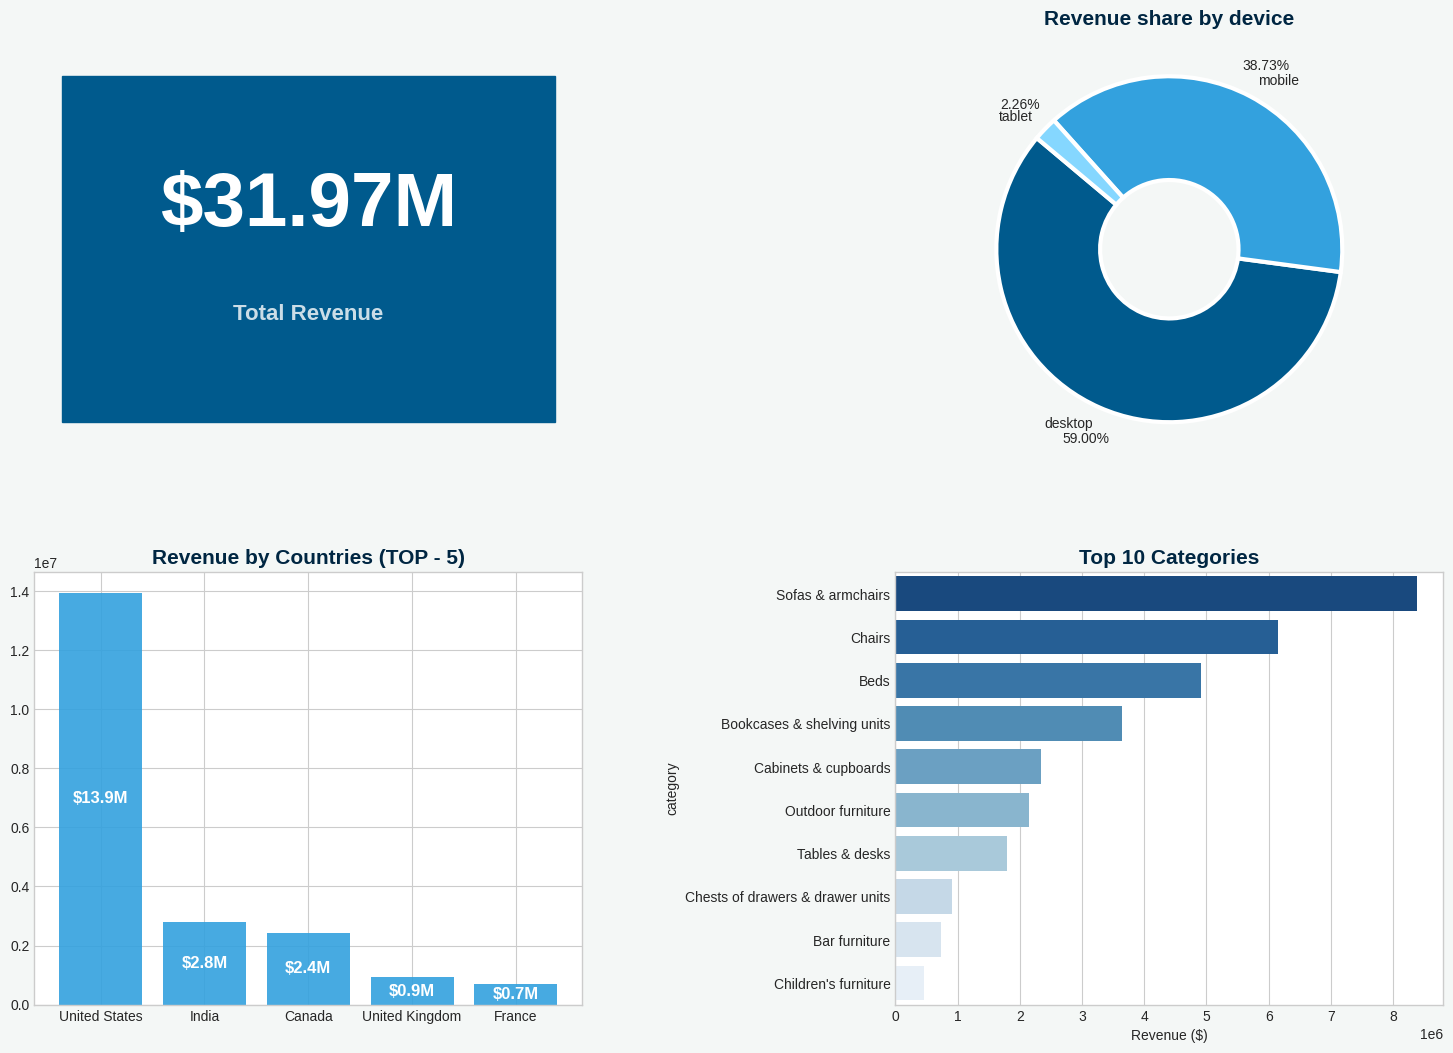

In [22]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor('#f4f7f6')

blue = '#005a8d'
light_blue = '#33a1de'

# 1. TOTAL Revenue
axes[0, 0].axis('off')
rect = plt.Rectangle((0.05, 0.1), 0.9, 0.8, color = blue, transform = axes[0, 0].transAxes, zorder = 1)
axes[0, 0].add_patch(rect)

axes[0, 0].text(0.5, 0.6, f'${total_revenue/1e6:.2f}M', fontsize = 55, fontweight = 'bold', ha = 'center', va = 'center', color = 'white', zorder = 2)
axes[0, 0].text(0.5, 0.35, 'Total Revenue', fontsize = 16, ha = 'center', va = 'center', fontweight = 'bold', color = 'white', alpha = 0.8, zorder = 2)

# 2. Revenue by device
axes[0, 1].pie(device_type_prcnt.values, labels = device_type_prcnt.index, autopct = '%1.2f%%', startangle = 140, colors = [blue, light_blue, '#85d7ff'], pctdistance = 1.2, wedgeprops ={'edgecolor': 'white', 'linewidth': 3, 'width': 0.6})
axes[0, 1].set_title('Revenue share by device', fontsize = 15, fontweight = 'bold', color = '#002642')

# 3. Top 5 Countries by revenue
bars = axes[1, 0].bar(top_countries_by_sales.index, top_countries_by_sales.values, color = light_blue, alpha = 0.9)
axes[1, 0].set_title('Revenue by Countries (TOP - 5)', fontsize = 15, fontweight = 'bold', color = '#002642')
for bar in bars:
    height = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2., height/2, f'${height/1e6:.1f}M', ha = 'center', va = 'center', color = 'white', fontweight = 'bold', fontsize = 12)

# 4. Top 10 categories
sns.barplot(x = revenue_categories.values, y = revenue_categories.index, ax = axes[1, 1], palette = 'Blues_r', hue = revenue_categories.index)
axes[1, 1].set_title('Top 10 Categories', fontsize = 15, fontweight = 'bold', color = '#002642')
axes[1, 1].set_xlabel('Revenue ($)')

plt.tight_layout(pad = 6.0)
plt.show()

#Conclusion
The analysis shows that the company's main profit comes from North America, especially from the USA. From there the company receives 43% of total revenue ($13.9 million). The geographical distribution of orders is fully correlated with revenue. This means, that we have a stable average check in our main regions  - the USA, India and Canada. However, such a strong share in the USA makes us dependent on the market of one country.
Therefore, it's important to develop the European direction, especially in the UK and France. There are many people interested in our products, but so far it brings less income.

Among our products there are clear leaders - upholstered furniture (Sofas&Armchairs, Chairs, Beds). Moreover, the categorical rating of products in the USA completely duplicates the global one, which suggests that the preferences of American buyers set trends for the whole world.

Regarding the technical point, despite the fact that quite a lot of users enter the site from a mobile device (almost 39%). However, most purchases are still made from computers (59%). This can be explained by the fact that furniture is usually expensive, and people want to see it on a big screen before buying. And the fact that many people come from organic search (35.7%) and direct (26.6%) shows that the brand is recognizable and the SEO strategy is working.

Regarding customer loyalty indicators, more than 71% of users confirm their email, which is a good indicator for CRM. A comparison of the two groups of users (who subscribe to our emails and those who unsubscribed) showed that their conversion rate is almost the same (about 10%) and ARPU indicators are also almost identical. This means that unsubscribing from emails doesn't affect the customer's solvency and desire to buy.

It can be concluded that current email marketing doesn't seem to be the main factor that pushes to purchase. People make their own decisions about ordering, focusing on the quality of the product or the convenience of the site.

Taking into account all the listed indicators, several solutions can be implemented. For example, for the US market, can be launched a loyalty program - this way company can increase traffic from anonymous users to registered ones. It's also important to check how the mobile version of the site works, especially on pages with top furniture categories, to consider ways to simplify payment. These implementations can increase revenue without additional costs for attracting new users.


#Sales Dynamic Analysis

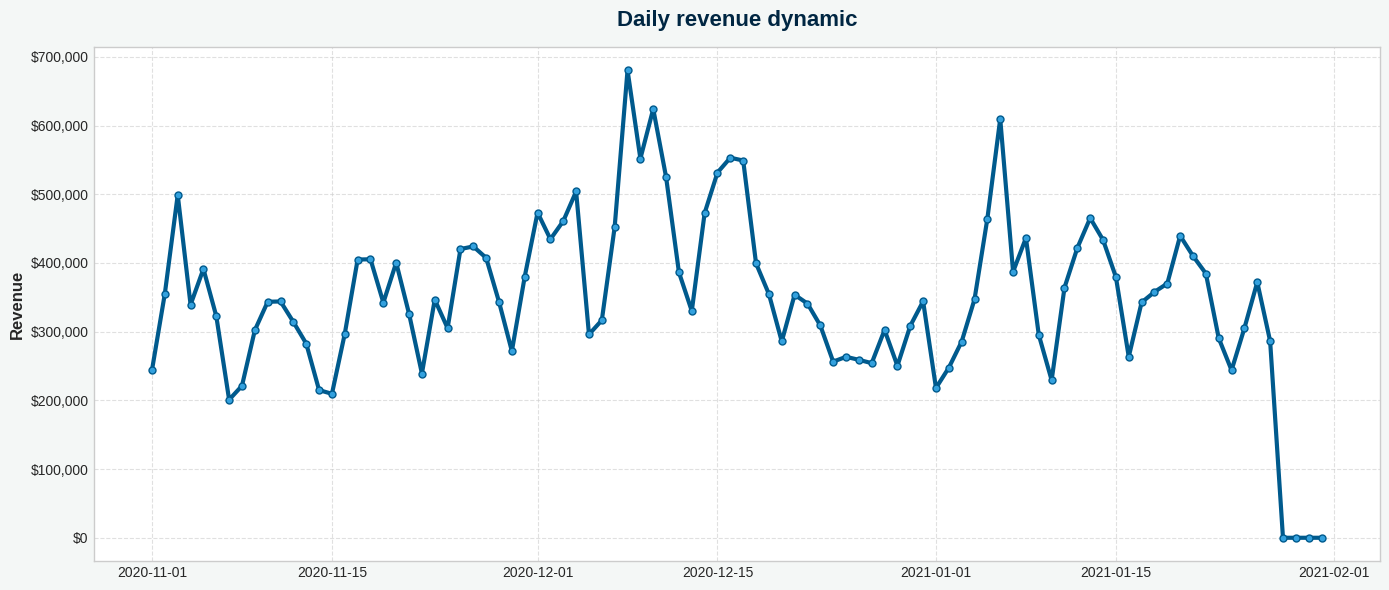

In [41]:
#Daily revenue dynamic
daily_sales = df.groupby('order_date')['price'].sum().reset_index()

fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor('#f4f7f6')

ax.plot(daily_sales['order_date'], daily_sales['price'], color = blue , linewidth = 3, marker = 'o',
        markersize = 5, markerfacecolor = '#33a1de')
ax.set_title('Daily revenue dynamic', fontsize = 16, fontweight = 'bold', color = '#002642', pad = 15)
ax.set_ylabel('Revenue', fontsize = 12, fontweight = 'bold')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.grid(True, linestyle = '--', alpha = 0.6)

plt.tight_layout()
plt.show()

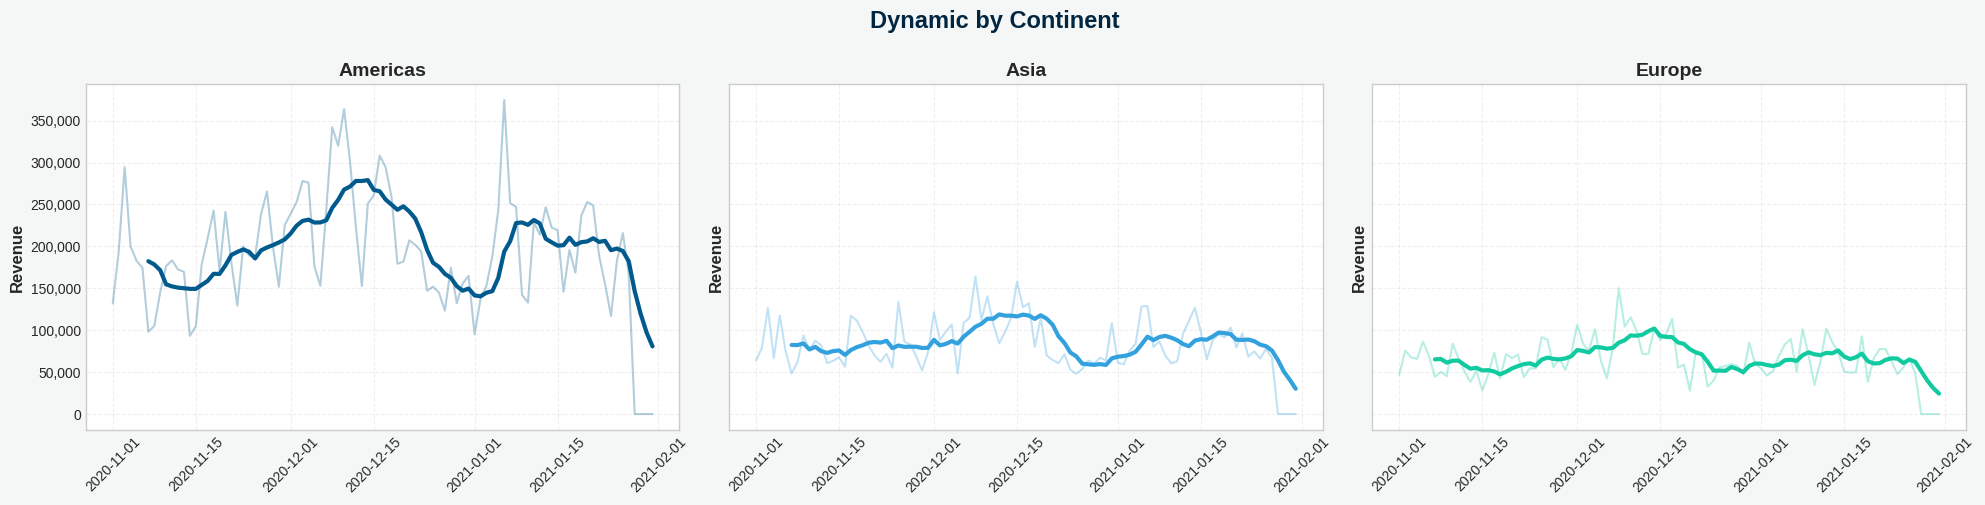

In [42]:
#Dynamic by Continent (Moving average = week)
top_3_cont = top_continents.index.tolist()

fig, axes = plt.subplots(1, 3, figsize = (20, 5), sharey = True)
colors = [blue, light_blue, '#11caa0']
fig.patch.set_facecolor('#f4f7f6')

for i, name in enumerate(top_3_cont):
  data = df[df['continent'] == name]
  daily_data = data.groupby('order_date')['price'].sum().reset_index()
  daily_data['smooth_price'] = daily_data['price'].rolling(window = 7).mean()

  axes[i].plot(daily_data['order_date'], daily_data['price'], color = colors[i], alpha = 0.3)
  axes[i].plot(daily_data['order_date'], daily_data['smooth_price'], color = colors[i], linewidth = 3)

  axes[i].set_title(name, fontsize = 14, fontweight =  'bold')
  axes[i].set_ylabel('Revenue', fontsize = 12, fontweight = 'bold')
  axes[i].tick_params(axis = 'x', rotation = 45)
  axes[i].yaxis.set_major_formatter('{x:,.0f}')
  axes[i].grid(True, linestyle = '--', alpha = 0.3)

fig.suptitle('Dynamic by Continent', fontsize = 17, fontweight = 'bold', y = 1, color = '#002642')
plt.tight_layout()
plt.show()

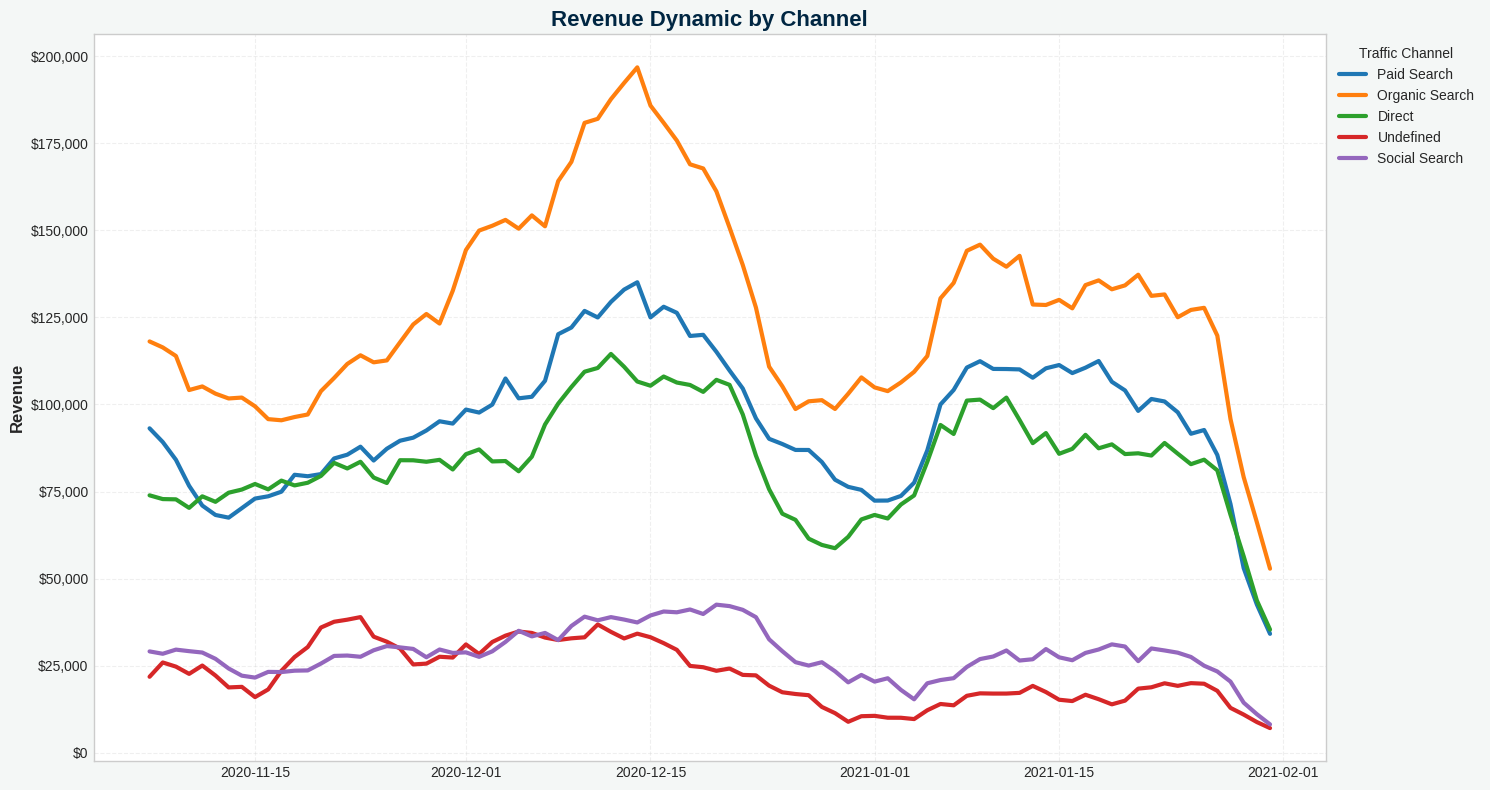

In [43]:
#Dynamic by traffic_channel (Moving average)
channels = df['traffic_channel'].unique()

fig, ax = plt.subplots(figsize = (15, 8))
fig.patch.set_facecolor('#f4f7f6')

for channel in channels:
  channel_data = df[df['traffic_channel'] == channel]
  daily_revenue = channel_data.groupby('order_date')['price'].sum().reset_index()
  daily_revenue['smooth'] = daily_revenue['price'].rolling(7).mean()
  plt.plot(daily_revenue['order_date'], daily_revenue['smooth'], label = channel, linewidth = 3)

plt.title('Revenue Dynamic by Channel', fontsize = 16, fontweight = 'bold', color = '#002642')
plt.ylabel('Revenue', fontsize = 12, fontweight = 'bold')
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.legend(title = 'Traffic Channel', bbox_to_anchor=(1, 1), loc = 'upper left')
plt.grid(True, linestyle = '--', alpha = 0.3)
plt.tight_layout()
plt.show()

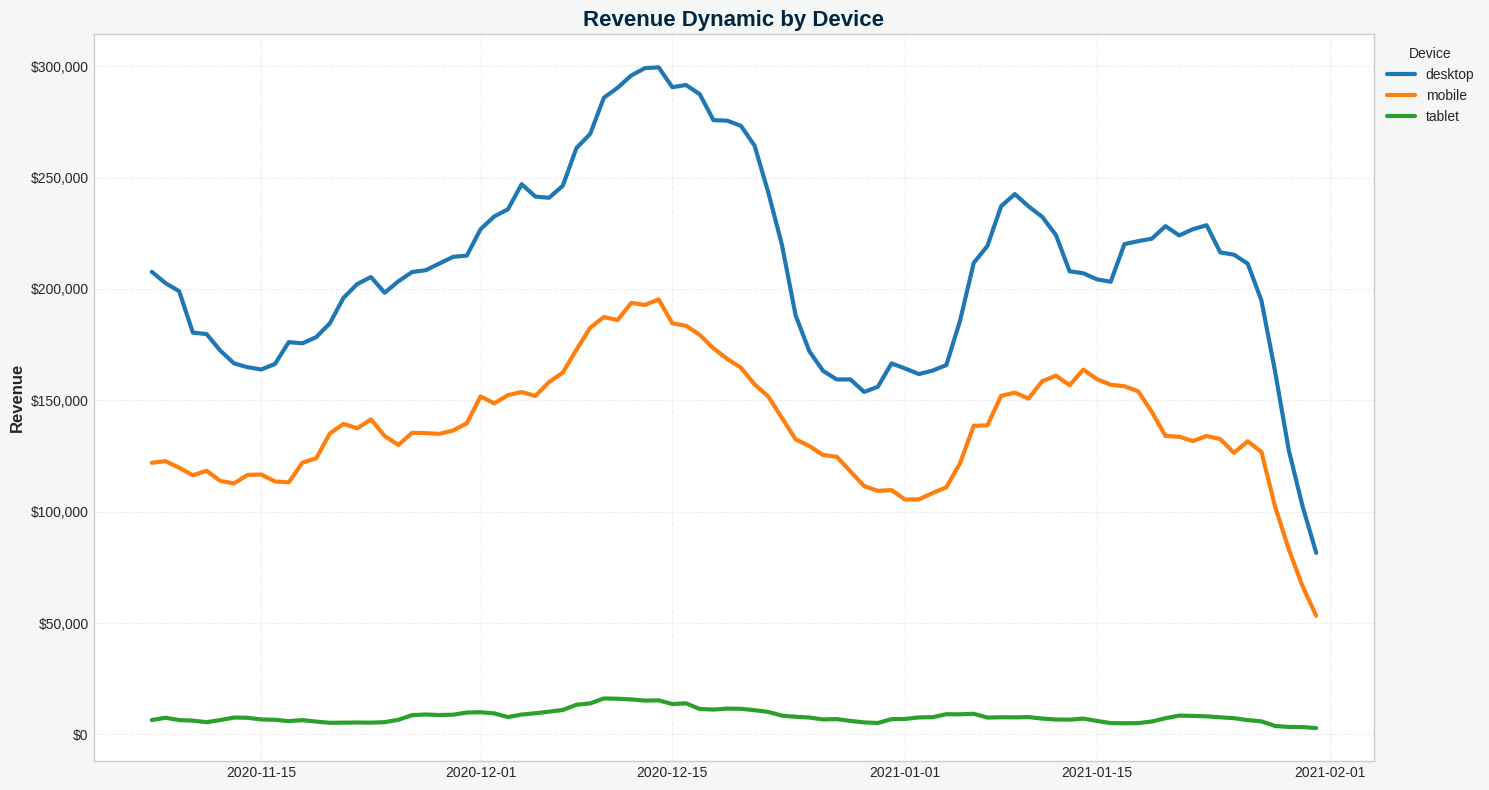

In [44]:
#Dynamic by device (Moving average)
devices = df['device'].unique()

fig, ax = plt.subplots(figsize = (15, 8))
fig.patch.set_facecolor('#f4f7f6')

for device in devices:
  device_data = df[df['device'] == device]
  daily_revenue = device_data.groupby('order_date')['price'].sum().reset_index()
  daily_revenue['smooth'] = daily_revenue['price'].rolling(7).mean()
  plt.plot(daily_revenue['order_date'], daily_revenue['smooth'], label = device, linewidth = 3)

plt.title('Revenue Dynamic by Device', fontsize = 16, fontweight = 'bold', color = '#002642')
plt.ylabel('Revenue', fontsize = 12, fontweight = 'bold')
plt.legend(title = 'Device', bbox_to_anchor = (1, 1), loc = 'upper left')
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.grid(True, linestyle = '--', alpha = 0.3)
plt.tight_layout()
plt.show()

#Conclusion
Based on the analysis of daily revenue, it can be seen that the dynamic demonstrates a clear cyclical structure with fluctuations every 7–8 days, confirming that users are accustomed to making purchases on specific days of the week. Holiday seasonality was also identified—in mid-December, pre-New Year sales reached nearly 700,000$ in profit, and a similar trend with a sharp surge followed by a decline until the end of January 2021 was observed across all continents.

Regarding geographical distribution, the key driver in terms of revenue is the Americas. Despite the fact that the continent is subject to sharp fluctuations in its metrics, its numbers still significantly outpace Europe and Asia combined. Asia and Europe move almost synchronously, but combined they still do not show significant figures. Due to the post-holiday lull, it is crucial for the company to stop active purchasing and manufacturing by mid-December to prevent warehouses from being overloaded with inventory. To maintain stability after the holiday boom, it is necessary to figure out how to keep customers interested, for example, by launching promotions or bonus programs.

In terms of traffic channels, organic search is the primary source of revenue; it also sets the trend for the remaining channels. This highlights how heavily the company depends on how well its internet search is optimized. The main channels—organic, paid search, and direct — demonstrate a high correlation. At the same time, social media and undefined traffic bring in almost no revenue (less than 50 thousand) and showed no reaction to the pre-New Year boom. An audit should be conducted on undefined traffic to understand exactly where these users are coming from. If optimizing social media doesn't increase its efficiency, it is better to stop utilizing this channel altogether and redirect its budget to the guaranteed profitability of paid search.

As for the devices used, most users log in from desktop. This is natural behavior for expensive and bulky goods (in our case, furniture). Therefore, any website updates and redesigns must first be tested on desktop type. Mobile metrics completely duplicate desktop ones — it is the second most important device, while tablet shows almost no dynamics or noticeable profitability. Investing in this device type is completely unviable. The company would be better off focusing on desktop and mobile development, such as implementing a mobile app to make it more comfortable for users to shop from their phones.


In [45]:
pivot_sessions = df.pivot_table(index = 'traffic_channel', columns = 'device', values = 'price', aggfunc='count')

print("Sessions by Traffic and Device")
display(pivot_sessions.style.format(formatter = "{:,.0f}"))

Sessions by Traffic and Device


device,desktop,mobile,tablet
traffic_channel,,,
Direct,"47,825","31,745","1,812"
Organic Search,"72,622","49,014","2,789"
Paid Search,"55,167","37,034","2,140"
Social Search,"16,288","10,988",638
Undefined,"12,527","8,486",470


In [46]:
top_categories = df.groupby('category')['price'].sum().sort_values(ascending=False).head(10).index
top_countries = df.groupby('country')['price'].sum().sort_values(ascending=False).head(5).index

pivot_categories = df[df['country'].isin(top_countries) & df['category'].isin(top_categories)].pivot_table(index='category',
columns='country',values='price', aggfunc = 'sum').reindex(index = top_categories, columns = top_countries)

print("Revenue by Countries and Categories")
display(pivot_categories.style.format(formatter = "${:,.0f}"))

Revenue by Countries and Categories


country,United States,India,Canada,United Kingdom,France
category,,,,,
Sofas & armchairs,"$3,707,144","$788,430","$692,428","$234,812","$187,735"
Chairs,"$2,619,774","$544,309","$417,741","$188,519","$134,029"
Beds,"$2,213,058","$358,320","$354,772","$133,816","$116,414"
Bookcases & shelving units,"$1,567,607","$364,507","$278,982","$113,988","$73,830"
Cabinets & cupboards,"$994,546","$191,888","$181,802","$71,684","$59,102"
Outdoor furniture,"$929,245","$162,289","$185,323","$57,002","$40,486"
Tables & desks,"$777,865","$186,158","$132,678","$49,374","$42,299"
Chests of drawers & drawer units,"$382,388","$73,111","$71,952","$36,784","$21,544"
Bar furniture,"$330,805","$57,657","$51,724","$22,103","$11,199"


In [47]:
df['day_name'] = pd.to_datetime(df['order_date']).dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

pivot_days = df[df['country'].isin(top_countries)].pivot_table(index = 'day_name', columns = 'country', values = 'price',
aggfunc='sum').reindex(index = days_order, columns = top_countries)

print("Revenue by Countries and Day name")
display(pivot_days.style.format(formatter = "${:,.0f}"))

Revenue by Countries and Day name


country,United States,India,Canada,United Kingdom,France
day_name,,,,,
Monday,"$2,018,236","$393,917","$366,188","$153,827","$119,254"
Tuesday,"$2,373,251","$483,408","$371,462","$165,178","$127,297"
Wednesday,"$2,449,078","$489,280","$416,010","$166,001","$92,524"
Thursday,"$2,181,668","$429,264","$388,510","$120,254","$129,527"
Friday,"$2,012,322","$369,043","$377,797","$136,619","$116,640"
Saturday,"$1,433,117","$282,601","$294,277","$84,765","$77,693"
Sunday,"$1,475,881","$362,249","$223,676","$111,674","$47,757"


In [48]:
pivot_sales = df[df['category'].isin(top_categories)].pivot_table(index = 'category', values = 'price', aggfunc = ['count', 'sum']
).reindex(index = top_categories)

pivot_sales.columns = ['Orders count', 'Total revenue']

print("Categories by Orders and Revenue")
display(pivot_sales.style.format(formatter = {'Orders count': '{:,.0f}', 'Total revenue': '${:,.0f}'}))


Categories by Orders and Revenue


,Orders count,Total revenue
category,,
Sofas & armchairs,"4,301","$8,388,254"
Chairs,"5,952","$6,147,749"
Beds,"2,926","$4,919,725"
Bookcases & shelving units,"7,630","$3,640,818"
Cabinets & cupboards,"2,318","$2,336,500"
Outdoor furniture,"2,229","$2,142,222"
Tables & desks,"2,941","$1,790,308"
Chests of drawers & drawer units,"1,452","$906,562"
Bar furniture,"1,092","$735,503"


#Statistical Analysis

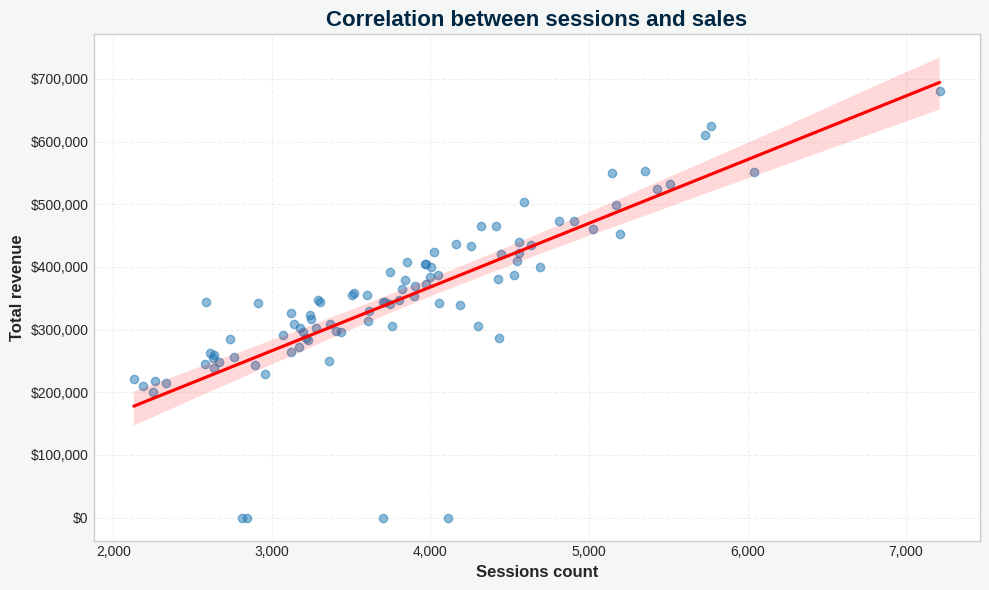

Pearson correlation coefficient: 0.791
Statistical significance (p-value): 6.483532312080735e-21
The correlation is statistically significant (p < 0.05).


In [49]:
#Relationship between sessions and sales by date
from scipy.stats import pearsonr

#Count sessions per date
sessions_per_date = df.groupby('order_date').size().reset_index(name = 'sessions_count')

#Count orders per date
sales_per_date = df[df['price'] > 0].groupby('order_date')['price'].sum().reset_index(name='total_sales')

#Join
correlation_df = pd.merge(sessions_per_date, sales_per_date, on = 'order_date', how = 'left')
correlation_df['total_sales'] = correlation_df['total_sales'].fillna(0)

#Correlation between sessions and sales
#plt.figure(figsize = (10, 6))
fig, ax = plt.subplots(figsize = (10, 6))
fig.patch.set_facecolor('#f4f7f6')
sns.regplot(data = correlation_df, x = 'sessions_count', y = 'total_sales', scatter_kws = {'alpha':0.5}, line_kws = {'color':'red'})
plt.title('Correlation between sessions and sales', fontsize = 16, fontweight = 'bold', color = '#002642')
plt.xlabel('Sessions count', fontsize = 12, fontweight = 'bold')
plt.ylabel('Total revenue', fontsize = 12, fontweight = 'bold')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.xaxis.set_major_formatter('{x:,.0f}')
plt.grid(True, linestyle = '--', alpha = 0.3)
plt.tight_layout()
plt.show()

#Calculating Pearson correlation and p value
corr_coef, p_value = pearsonr(correlation_df['sessions_count'], correlation_df['total_sales'])

print(f"Pearson correlation coefficient: {corr_coef:.3f}")
print(f"Statistical significance (p-value): {p_value}")

if p_value < 0.05:
    print("The correlation is statistically significant (p < 0.05).")
else:
    print("The correlation is not statistically significant.")

In [50]:
#Correlation between continents
cont_pivot = df[df['continent'].isin(top_3_cont)].pivot_table(index = 'order_date', columns = 'continent', values = 'price',
aggfunc='sum').fillna(0)

cont = cont_pivot.columns
c1, c2, c3 = cont[0], cont[1], cont[2]

print(f"Correlation between Continents: {c1}, {c2}, {c3}")

#Americas & Asia
corr1, p1 = pearsonr(cont_pivot[c1], cont_pivot[c2])
print(f"\n{c1} & {c2}:")
print(f"Correlation: {corr1:.3f}, p-value: {p1}")
print(f"Significant: {p1 < 0.05}")

#Americas & Europe
corr2, p2 = pearsonr(cont_pivot[c1], cont_pivot[c3])
print(f"\n{c1} & {c3}:")
print(f"Correlation: {corr2:.3f}, p-value: {p2}")
print(f"Significant: {p2 < 0.05}")

#Asia & Europe
corr3, p3 = pearsonr(cont_pivot[c2], cont_pivot[c3])
print(f"\n{c2} & {c3}:")
print(f"Correlation: {corr3:.3f}, p-value: {p3}")
print(f"Significant: {p3 < 0.05}")

Correlation between Continents: Americas, Asia, Europe

Americas & Asia:
Correlation: 0.792, p-value: 5.409189396197475e-21
Significant: True

Americas & Europe:
Correlation: 0.771, p-value: 2.6714492240629956e-19
Significant: True

Asia & Europe:
Correlation: 0.768, p-value: 3.8649460090531196e-19
Significant: True


In [51]:
#Correlation between traffic channels
traffic_pivot = df.pivot_table(index = 'order_date', columns = 'traffic_channel', values = 'price', aggfunc = 'sum').fillna(0)

traffic = traffic_pivot.columns
ch1, ch2, ch3 = traffic[0], traffic[1], traffic[2]

print(f"Correlation between Traffic Channels: {ch1}, {ch2}, {ch3}")

#Direct & Organic Search
corr1, p1 = pearsonr(traffic_pivot[ch1], traffic_pivot[ch2])
print(f"\n{ch1} & {ch2}:")
print(f"Correlation: {corr1:.3f}, p-value: {p1}")
print(f"Significant: {p1 < 0.05}")

#Direct & Paid Search
corr2, p2 = pearsonr(traffic_pivot[ch1], traffic_pivot[ch3])
print(f"\n{ch1} & {ch3}:")
print(f"Correlation: {corr2:.3f}, p-value: {p2}")
print(f"Significant: {p2 < 0.05}")

#Organic Search & Paid Search
corr3, p3 = pearsonr(traffic_pivot[ch2], traffic_pivot[ch3])
print(f"\n{ch2} & {ch3}:")
print(f"Correlation: {corr3:.3f}, p-value: {p3}")
print(f"Significant: {p3 < 0.05}")

Correlation between Traffic Channels: Direct, Organic Search, Paid Search

Direct & Organic Search:
Correlation: 0.838, p-value: 2.1904196603645366e-25
Significant: True

Direct & Paid Search:
Correlation: 0.814, p-value: 5.896434878977516e-23
Significant: True

Organic Search & Paid Search:
Correlation: 0.870, p-value: 2.1420029219324783e-29
Significant: True


In [52]:
#Correlation between  top 5 categories
top_5_categ = df.groupby('category')['price'].sum().nlargest(5).index

category_sales = df[df['category'].isin(top_5_categ)].pivot_table(index = 'order_date', columns = 'category', values = 'price',
aggfunc='sum').fillna(0)

categ = category_sales.columns
ca1, ca2, ca3, ca4, ca5 = categ[0], categ[1], categ[2], categ[3], categ[4]

print(f"Correlation between Categories: {ca1}, {ca2}, {ca3}, {ca4}, {ca5}")

#Beds vs Bookcases & shelving units
corr1, p1 = pearsonr(category_sales[ca1], category_sales[ca2])
print(f"\n{ca1} vs {ca2}: \nCorrelation: {corr1:.3f}, p-value: {p1}, Significant: {p1 < 0.05}")

#Beds vs Cabinets & cupboards
corr2, p2 = pearsonr(category_sales[ca1], category_sales[ca3])
print(f"\n{ca1} vs {ca3}: \nCorrelatio {corr2:.3f}, p-value: {p2}, Significant: {p2 < 0.05}")

#Beds vs Chairs
corr3, p3 = pearsonr(category_sales[ca1], category_sales[ca4])
print(f"\n{ca1} vs {ca4}: \nCorrelation {corr3:.3f}, p-value: {p3}, Significant: {p3 < 0.05}")

#Beds vs Sofas & armchairs
corr4, p4 = pearsonr(category_sales[ca1], category_sales[ca5])
print(f"\n{ca1} vs {ca5}: \nCorrelation: {corr4:.3f}, p-value: {p4}, Significant: {p4 < 0.05}")

#Bookcases & shelving units vs Cabinets & cupboards
corr5, p5 = pearsonr(category_sales[ca2], category_sales[ca3])
print(f"\n{ca2} vs {ca3}: \nCorrelation: {corr5:.3f}, p-value: {p5}, Significant: {p5 < 0.05}")

#Bookcases & shelving units vs Chairs
corr6, p6 = pearsonr(category_sales[ca2], category_sales[ca4])
print(f"\n{ca2} vs {ca4}: \nCorrelation: {corr6:.3f}, p-value: {p6}, Significant: {p6 < 0.05}")

#Bookcases & shelving units vs Sofas & armchairs
corr7, p7 = pearsonr(category_sales[ca2], category_sales[ca5])
print(f"\n{ca2} vs {ca5}: \nCorrelation: {corr7:.3f}, p-value: {p7}, Significant: {p7 < 0.05}")

#Cabinets & cupboards vs Chairs
corr8, p8 = pearsonr(category_sales[ca3], category_sales[ca4])
print(f"\n{ca3} vs {ca4}: \nCorrelation: {corr8:.3f}, p-value: {p8}, Significant: {p8 < 0.05}")

#Cabinets & cupboards vs Sofas & armchairs
corr9, p9 = pearsonr(category_sales[ca3], category_sales[ca5])
print(f"\n{ca3} vs {ca5}: \nCorrelation: {corr9:.3f}, p-value: {p9}, Significant: {p9 < 0.05}")

#Chairs vs Sofas & armchairs
corr10, p10 = pearsonr(category_sales[ca4], category_sales[ca5])
print(f"\n{ca4} vs {ca5}: \nCorrelation: {corr10:.3f}, p-value: {p10}, Significant: {p10 < 0.05}")

Correlation between Categories: Beds, Bookcases & shelving units, Cabinets & cupboards, Chairs, Sofas & armchairs

Beds vs Bookcases & shelving units: 
Correlation: 0.593, p-value: 1.1549982399950595e-09, Significant: True

Beds vs Cabinets & cupboards: 
Correlatio 0.515, p-value: 2.9109296191322004e-07, Significant: True

Beds vs Chairs: 
Correlation 0.554, p-value: 2.079182865492252e-08, Significant: True

Beds vs Sofas & armchairs: 
Correlation: 0.535, p-value: 7.687332925177328e-08, Significant: True

Bookcases & shelving units vs Cabinets & cupboards: 
Correlation: 0.539, p-value: 5.8672250979394714e-08, Significant: True

Bookcases & shelving units vs Chairs: 
Correlation: 0.637, p-value: 2.5045503773672356e-11, Significant: True

Bookcases & shelving units vs Sofas & armchairs: 
Correlation: 0.666, p-value: 1.4069719486806666e-12, Significant: True

Cabinets & cupboards vs Chairs: 
Correlation: 0.573, p-value: 5.46590349515409e-09, Significant: True

Cabinets & cupboards vs Sofa

In [53]:
# Correlation between top 2 countries
top_2_countries = df.groupby('country')['price'].sum().nlargest(2).index

country_pivot = df[df['country'].isin(top_2_countries)].pivot_table(index = 'order_date', columns = 'country', values = 'price',
aggfunc='sum').fillna(0)

countries = country_pivot.columns
coun1, coun2 = countries[0], countries[1]

corr_c, p_c = pearsonr(country_pivot[coun1], country_pivot[coun2])

print(f"Correlation between: {coun1} & {coun2}")
print(f"Correlation: {corr_c:.3f}, p-value: {p_c}")
print(f"Significant: {p_c < 0.05}")

Correlation between: India & United States
Correlation: 0.678, p-value: 1.0930884956965336e-13
Significant: True


#Conclusion
The correlation analysis shows that the number of sessions and daily sales volume have a strong positive linear relationship, with a Pearson correlation coefficient of 0.791 and a statistical significance of p < 0.05, which completely rules out the element of chance. The charts indicate that the model is generally stable, but there were some critical anomalies where, despite high traffic, there were no sales at all. This points to technical issues, such as a malfunction in the payment system or a checkout cart failure. Since the link between traffic and sales is strong, investing money in visitor acquisition can help increase revenue.

Global sales factors demonstrate a high degree of geographical synchronicity, as evidenced by a strong linear relationship between key markets, where the correlation between the Americas and Asia is 0.792, between the Americas and Europe is 0.771, and between Asia and Europe is 0.768, with all p-value indicators approaching absolute zero. Even between countries like India and the United States, sales show a moderate-to-strong correlation despite being on different continents. This synchronicity suggests that customers worldwide share similar behavioral patterns, and sales are heavily influenced by shared events, such as the New Year holiday season.

An analysis of different traffic acquisition channels revealed that they operate as a single, well-coordinated system. The correlation between organic and paid search reaches 0.870, between direct traffic and organic search is 0.838, and between direct  and paid search is 0.814. This implies that the commercial metrics of various sources move practically in tandem: when revenue from one channel grows, sales through other sources are highly likely to increase proportionally. At the same time, the relationship between the top 5 product categories in the furniture segment is moderate, ranging from 0.51 to 0.67. Bookcases & shelving units and sofas & armchairs are the most closely linked (0.666), followed by cabinets & cupboards and sofas & armchairs (0.658). The weakest link is observed between beds and cabinets & cupboards (0.515). This moderate-to-high correlation level indicates that different product categories develop in parallel under the influence of shared market factors, yet still maintain a certain degree of internal independence.


#Statistical Anlysysis between groups

In [54]:
from scipy import stats

#Analysis between registered and guests users
df['is_registered'] = df['account_id'].notna()

#Calculating total sales
registered_sales = df[df['is_registered'] == True].groupby('order_date')['price'].sum()
guest_sales = df[df['is_registered'] == False].groupby('order_date')['price'].sum()

# Test Shapiro-Wilk
_, p_reg = stats.shapiro(registered_sales)
_, p_guest = stats.shapiro(guest_sales)

print(f"P-value of normality: \nRegistered: {p_reg} \nGuests: {p_guest}")

# Test Mann-Whitney
stat, p_val = stats.mannwhitneyu(registered_sales, guest_sales)

print(f"\nAverage revenue per day: \nRegistered: ${registered_sales.mean():,.2f} \nGuests: ${guest_sales.mean():,.2f}")

print(f"\nP-value Mann-Whitney test: {p_val}")

if p_val < 0.05:
    print("The difference between the groups is statistically significant.")
else:
    print("The difference between the groups isn't statistically significant.")

P-value of normality: 
Registered: 0.007295139880540744 
Guests: 0.0012184604855253293

Average revenue per day: 
Registered: $29,346.80 
Guests: $319,447.96

P-value Mann-Whitney test: 3.8805185465235906e-26
The difference between the groups is statistically significant.


In [55]:
#Analysis sessions by traffic channel
channels = df.groupby(['order_date', 'traffic_channel']).size().unstack(fill_value=0)

samples = [channels[col] for col in channels.columns]

#Test Kruskel-Wallis
stat, p_val = stats.kruskal(*samples)
print(f"Analysis Sessions by Traffic channel: \np-value: {p_val}")

print("\nAverage Daily Sessions by Traffic channel")
print(channels.mean().sort_values(ascending = False).map('{:,.2f}'.format))


Analysis Sessions by Traffic channel: 
p-value: 1.397036102599359e-78

Average Daily Sessions by Traffic channel
traffic_channel
Organic Search    1,352.45
Paid Search       1,025.45
Direct              884.59
Social Search       303.41
Undefined           233.51
dtype: object


In [56]:
from statsmodels.stats.proportion import proportions_ztest

#Share difference of sessions from organic traffic in Europe and America
continent_1 = 'Europe'
continent_2 = 'Americas'

# Calculating total sessions
total_cont1 = len(df[df['continent'] == continent_1])
total_cont2 = len(df[df['continent'] == continent_2])

# Calculating sessions from orranic search
organic_cont1 = len(df[(df['continent'] == continent_1) & (df['traffic_channel'] == 'Organic Search')])
organic_cont2 = len(df[(df['continent'] == continent_2) & (df['traffic_channel'] == 'Organic Search')])


share_c1 = organic_cont1 / total_cont1
share_c2 = organic_cont2 / total_cont2

print("Organic sessions percent from total:")
print(f"{continent_1}: Organic search: {organic_cont1:,} from {total_cont1:,} sessions ({share_c1:.2%})")
print(f"{continent_2}: Organic search: {organic_cont2:,} from {total_cont2:,} sessions ({share_c2:.2%})")

# Z-test
counts = [organic_cont1, organic_cont2]
nobs = [total_cont1, total_cont2]

z_stat, p_value = proportions_ztest(counts, nobs)

print(f"\nZ-statistics: {z_stat:.4f}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("The difference isn't statistically significant.")

Organic sessions percent from total:
Europe: Organic search: 23,195 from 65,135 sessions (35.61%)
Americas: Organic search: 68,671 from 193,179 sessions (35.55%)

Z-statistics: 0.2895
p-value: 0.7721879690501752
The difference isn't statistically significant.


In [57]:
#Difference between weekday and weekend sessions
df['is_weekend'] = pd.to_datetime(df['order_date']).dt.dayofweek.isin([5, 6])

weekday_sessions = df[df['is_weekend'] == False].groupby('order_date').size()
weekend_sessions = df[df['is_weekend'] == True].groupby('order_date').size()

# Student's t-test
t_stat, p_weekend = stats.ttest_ind(weekday_sessions, weekend_sessions)

print("Analysis Weekday & Weekend")
print(f"\nAverage number of sessions: \nWeekday: {weekday_sessions.mean():,.0f} \nWeekend: {weekend_sessions.mean():,.0f}")

print(f"\np-value: {p_weekend}")

Analysis Weekday & Weekend

Average number of sessions: 
Weekday: 4,159 
Weekend: 2,934

p-value: 9.311402187809796e-10


#Conclusion
An analysis of the daily sales volume distribution using the Shapiro-Wilk test revealed a non-normal distribution of data in both groups, which prompted the use of the Mann-Whitney U test. This test confirmed a high statistical significance of the differences between the samples, completely ruling out the element of chance. The resulting data clearly indicates that anonymous guests are the absolute leaders in driving the company's revenue. In this case, the company should make the purchasing process as simple as possible—for example, by introducing a guest checkout option without mandatory registration or by offering discounts on purchases upon account creation.

Concurrently, a comparison of the daily number of sessions across traffic sources using the Kruskal-Wallis test recorded statistically significant differences in audience acquisition volumes. Organic Search is the primary traffic driver with 1,352.45 sessions, whereas the Social Search (303.41) and Undefined (233.51) channels demonstrate the lowest efficiency.

At the same time, an analysis of the shares of organic traffic sessions across two key continents using a Z-test demonstrated consistency, as the share stands at 35.61% in Europe and 35.55% in the Americas. The resulting p-value proves a complete absence of any statistically significant difference. This implies that the brand is equally well-recognized on both continents and that search engine optimization works just as effectively. Therefore, there is no need to spend extra money on separate SEO strategies for each region; instead, the same successful approaches can be confidently applied everywhere.

On the other hand, a comparison of the daily number of sessions using Student's t-test revealed a deep disproportion between activity on weekdays and weekends, where an extremely small p-value indicates the absolute reliability of the result. On weekdays, the average site traffic is 4,159 sessions, whereas on weekends it drops by approximately 30% (2,934). This demonstrates typical seasonality throughout the week. Consequently, the company should plan its main promotions, newsletters, and new content for weekdays when customers are most active, while reducing the intensity of paid traffic on weekends.

#Total Conclusion
The analysis revealed that global sales are synchronized, as well as the company's strong dependence on the US market and organic search. The main growth potential lies in developing the European direction, optimizing the mobile version of the website to retain customers, and introducing loyalty programs for the predominant number of anonymous users to increase profit. Implementing the above will allow the company to depend less on a single region, smooth out the post-holiday decline, and increase conversion without tangible costs for attracting new customers.

In [58]:
df.to_csv('store_online.csv', index=False)

#Dashboard

In [59]:
from IPython.display import IFrame

dashboard_url = "https://public.tableau.com/views/Onlinestoresalesanalyticsdashboard/OnlineStoreAnalysis?:showVizHome=no&:embed=true"

IFrame(dashboard_url, width="100%", height=800)

Dashboard is published on Tableau Public: https://public.tableau.com/app/profile/elmira.mamiedova/viz/Onlinestoresalesanalyticsdashboard/OnlineStoreAnalysis
